# Laboratorio 1 de Tecnicas de Aprendizaje Automatico
## **Predicción de la Calidad del Vino: Clasificación vs Regresión**

### **Introducción**

Utilizando un conjunto de datos sobre la calidad del vino vamos a predecir la calidad de un vino a partir de diferentes propiedades

Para resolver este problema se plantean dos tipos diferentes de modelado:

* **Regresión**, tratando la calidad del vino como una **variable continua** que puede tomar distintos valores numéricos.
* **Clasificación**, tratando la calidad del vino como una **variable categórica**, donde cada valor representa una clase de calidad.

Vamos a entrenar y evaluar de varios modelos para cada uno de estos enfoques, analizar su rendimiento mediante diferentes métricas y comparar los resultados obtenidos.

#### **Conjunto de datos**

Los datos se obtienen mediante la librería **ucimlrepo**.

La variable objetivo es **quality**, que será la calidad del vino evaluada mediante una puntuación.

#### **Pasos principales**:

1. **Carga y exploración del dataset**, donde vamos a ver y comprender la estructura de los datos.
2. **Preprocesamiento de los datos**.
3. **Entrenamiento de modelos de aprendizaje automático y evaluación del rendimiento de los modelos**
4. **Comparación de resultados** entre ambos enfoques para analizar cuál se ajusta mejor al problema.



### **Importación de librerías**

Las principales librerías utilizadas han sido:

* **numpy** y **pandas**, para la manipulación y análisis de datos.
* **matplotlib**, para la visualización de datos mediante gráficos.

* **sklearn**, para trabajar los datos.

* **ucimlrepo**, para descargar fácilmente el dataset que vamos a utilizar.

In [1064]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import classification_report # Metrica para evaluar el modelo de clasificacion

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # Metricas para evaluar el modelo de regresion

from ucimlrepo import fetch_ucirepo

Añadimos este from para ayudar a la busqueda del mejor hiperparametro de cada modelo

In [1065]:
from sklearn.model_selection import GridSearchCV

## **1. Carga del dataset**

**fetch_ucirepo()** de la librería **ucimlrepo** descarga el conjunto de datos y se separa en:

* **x**: en la variable x guardamos las variables características del vino.
* **y**: en la variable y guardamos la variable objetivo, que corresponde a la calidad del vino.


In [1066]:
# Descarga del dataset
wine_quality = fetch_ucirepo(id=186)

# Datos brutos en formato Dataframe de pandas
x = wine_quality.data.features # Caracteristicas del vino
y = wine_quality.data.targets # Calidad del vino

In [1067]:
# Metadatos
print(wine_quality.metadata)

# Información de las variables
print(wine_quality.variables)


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

De los metadatos obtenidos se pueden observar varias características relevantes del dataset:
* Hay 11 variables de entrada del vino.
* La variable objetivo es quality, que representa una puntuación de calidad basada en evaluaciones sensoriales.
* Puede utilizarse tanto para problemas de clasificación como de regresión.

## **2. Preprocesamiento de los datos**.

### **Construcción del DataFrame del dataset**

Para facilitar el análisis se han combinado las variables del vino (x) y la variable objetivo (y) en un único DataFrame. Permitiendo visualizar el conjunto de datos completo.

Posteriormente se muestran las primeras filas del dataset para observar su estructura.


In [1068]:
df_wine = pd.DataFrame(data=pd.concat([x, y], axis=1)) # Une por columnas las variables del vino (x) y la calidad su calidad (y)

df_wine.head() # Muestra las primeras 5 filas 

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Numero total de vinos que hay de cada calidad
Vemos cuántas muestras existen para cada nivel de calidad del vino. Analizar esta distribución es importante, especialmente para clasificación.

A continuación se muestra el número de vinos presentes en cada categoría de calidad.

In [1069]:
df_wine["quality"].value_counts() # Cuenta cuantas veces aparece cada valor de calidad de vino.

quality
6    2836
5    2138
7    1079
4     216
8     193
3      30
9       5
Name: count, dtype: int64

### **Matriz de correlación entre variables**

Vamos a analizar la relación entre las variables del dataset. La matriz de correlación permite observar qué variables están más relacionadas entre sí.

La correlación mide el grado de relación lineal entre dos variables y toma valores entre -1 y 1, cuanto mas cerca de estos mayor es la correlación.

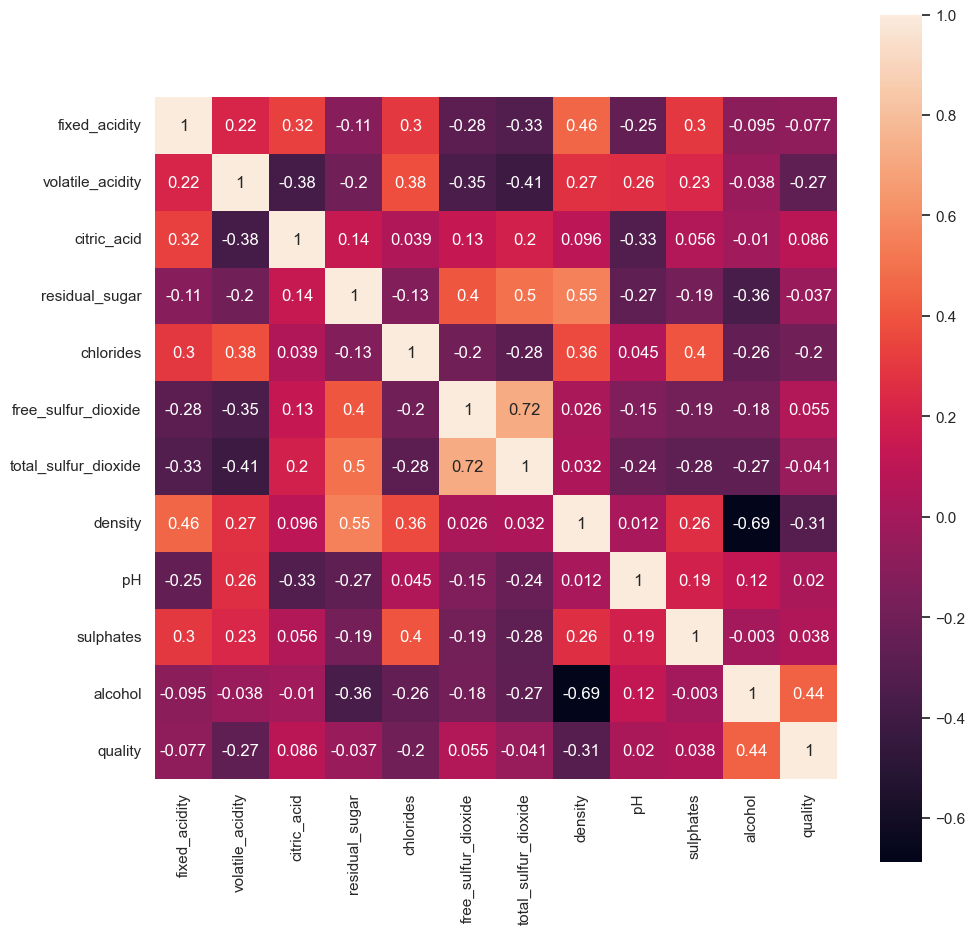

In [1070]:
import seaborn as sns # Libreria de visualización

sns.set() 
plt.figure(figsize=(11,11)) # Para cambiar el tamaño de la figura
sns.heatmap(df_wine.corr(), square=True, annot=True) # Calcula la matriz de correlación entre todas las variables numéricas del dataset (annot sirve para que los valores numéricos de la correlación aparezcan escritos)
plt.show()

### Analisis de la matriz
En este punto observamos la matriz, como podemos ver no encontramos valores extremadamente cercanos a 1 o -1, exceptuando la diagonal que no la debemos tener en cuenta, por lo que podemos seguir sin la necesidad de tener que eliminar columnas/variables que genere redundancia.

### **División del dataset en entrenamiento y prueba**

Es necesario dividir el conjunto de datos en dos partes:

* **Conjunto de entrenamiento**: se utiliza para que el modelo aprenda los patrones presentes en los datos.
* **Conjunto de prueba**: se utiliza para evaluar el rendimiento del modelo con datos que no se han utilizado en el entrenamiento.

Esta separación permite comprobar la capacidad del modelo para generalizar nuevos datos y evita el overfitting (Memorizar el dataset).


In [1071]:
# Separamos las variables de entrada (X) y la variable objetivo (y), pero antes:
#   - Eliminamos la columna "quality" de las variables de entrada y la utilizamos como variable a predecir 
#   - Utilizamos un 80% de las muestras del dataset para entrenamiento
x_train, x_test, y_train, y_test = train_test_split(df_wine.drop("quality", axis=1), df_wine["quality"], test_size=0.2, random_state=42)

### **Escalado**

Muchas variables pueden estar en distintas escalas.

El escalado permite que todas las variables tengan una escala similar, evitando que aquellas con valores más grandes dominen el proceso de aprendizaje del modelo.

In [1072]:
scaler = StandardScaler() # Transforma los datos para que tengan media 0 y desviación estándar 1
train = scaler.fit_transform(x_train) # Transforma los datos aplicando el escalado
test = scaler.transform(x_test) # Utiliza las mismas medias y desviaciones calculadas con el entrenamiento.

## **3. Entrenamiento de modelos de aprendizaje automático y evaluación del rendimiento de los modelos**

## 3.1 Clasificación

### 3.1.1 KNN Clasificación

In [1073]:
# Importamos el modelo KNN para clasificación
from sklearn.neighbors import KNeighborsClassifier 

#### <u>Sin busqueda de hiperparametros</u>

En primer lugar, entrenamos un modelo KNN utilizando sus valores por defecto, estableciendo únicamente el número de vecinos en 5.

Este modelo nos servirá como referencia para comparar posteriormente sus resultados con los obtenidos después de realizar la búsqueda de los mejores hiperparámetros.

In [1074]:
knn_clas = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

##### **Entrenamiento**

Se entrena el modelo utilizando los datos de entrenamiento previamente escalados. Durante este proceso, el algoritmo almacena las muestras y sus correspondientes clases de calidad para utilizarlas posteriormente al realizar predicciones.

In [1075]:
# Entrena el modelo con datos de entrenamiento escalados y las etiquetas de calidad del vino
knn_clas.fit(train, y_train) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",-1


##### **Prediccion**

Una vez entrenado el modelo, se utiliza el conjunto de prueba para predecir la calidad de los vinos que no ha visto anteriormente.

Las predicciones se almacenan en una nueva variable para poder evaluar el rendimiento del modelo.

In [1076]:
# Predecimos las clases del conjunto de prueba
y_pred_knn_clas = knn_clas.predict(test)

##### **Evaluacion**

In [1077]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report KNN ===")
print(classification_report(y_test, y_pred_knn_clas, labels=knn_clas.classes_, zero_division=0))

=== Classification Report KNN ===
              precision    recall  f1-score   support

           3       0.33      0.17      0.22         6
           4       0.27      0.14      0.18        43
           5       0.54      0.65      0.59       402
           6       0.58      0.59      0.58       597
           7       0.51      0.40      0.44       215
           8       0.20      0.08      0.12        36
           9       0.00      0.00      0.00         1

    accuracy                           0.55      1300
   macro avg       0.35      0.29      0.31      1300
weighted avg       0.53      0.55      0.53      1300



##### **Evaluación: Matriz de confusión**

La matriz de confusión permite comparar las clases reales con las clases predichas por el modelo KNN.

- Las filas representan las clases reales.

- Las columnas representan las clases predichas.

De esta manera podemos observar cuántas predicciones son correctas y en qué categorías se producen más errores.

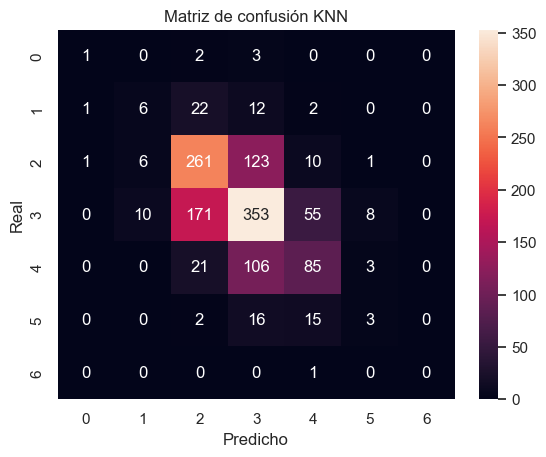

In [1078]:
# Importamos la función para crear la matriz de confusión
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Creamos la matriz comparando valores reales vs predichos
cm = confusion_matrix(y_test, y_pred_knn_clas)

# Dibujamos la matriz como mapa de calor
sns.heatmap(cm, annot=True, fmt="d")

# Títulos del gráfico
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicho")
plt.ylabel("Real")

# Mostrar gráfico
plt.show()

#### <u>Con búsqueda de hiperparámetros</u>

Clasifica una nueva muestra observando las K muestras más cercanas en el espacio de características y asignando la clase más frecuente entre ellas.

El rendimiento del modelo depende de varios **hiperparámetros**:

* n_neighbors (K): número de vecinos.
* weights: tipos de pesos.
* metric: metrica de distancia.

Buscamos la mejor combinación de hiperparámetros iterando sobre distintos valores posibles, evaluando cada modelo mediante **validación cruzada (cross-validation)** con 4 particiones y seleccionamos la combinación que obtiene la mejor precisión media.


In [1079]:
# Possible parameters
neighbors_range = range(1, 31) # Para probar valores de K entre 1 y 30
weights_options = ['uniform', 'distance']
metric_options = ['euclidean', 'manhattan']

best_score = 0 # Guarda la mejor precision 
best_params = {} # Parametros que producen esa mejor precision

# Bucles para probar combinaciones
for weight in weights_options:
    for metric_option in metric_options:
        for neighbors in neighbors_range:

          knn_clas_grid = KNeighborsClassifier(n_neighbors=neighbors, weights=weight, metric=metric_option) # Crea el modelo con la combinación actual de parámetros.
          # Hace cross validation con 4 particiones, con 3 entrena y con 1 evalua
          scores = cross_val_score(knn_clas_grid, train, y_train, cv=4) 
          mean_score = scores.mean() # Calcula la precision media del modelo
                
          if mean_score > best_score: # Compara si la precision media calculada es mejor el guardado como mejor
              best_score = mean_score # Se pone como mejor precision el calculado en este momento
              best_params = {'n_neighbors': neighbors, 'weights': weight, 'metric': metric_option} # Guardamos los parametros de la actual mejor precision


print("Best parameters:", best_params)
print("Best cross-validation score:", best_score)

Best parameters: {'n_neighbors': 28, 'weights': 'distance', 'metric': 'manhattan'}
Best cross-validation score: 0.6507616805826968


Se selecciona la combinación que ha obtenido el mejor rendimiento utilizando la búsqueda de hiperparámetros mediante validación cruzada. 

Con estos valores óptimos se construye el modelo final de KNN, que será entrenado utilizando el conjunto de datos de entrenamiento.


In [1080]:
# Parametros
n_neighbors = best_params["n_neighbors"]
weights = best_params["weights"]
metric = best_params["metric"]

# Fijamos la mejor combinacion encontrada
knn_clas_grid = KNeighborsClassifier(n_neighbors= n_neighbors, weights=weights, metric = metric)

##### **Entrenamiento**

In [1081]:
# Entrena el modelo con datos de entrenamiento escalados y las etiquetas de calidad del vino
knn_clas_grid.fit(train, y_train) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",28
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


##### **Predicción**

Una vez entrenado el modelo KNN con los mejores hiperparámetros, se utiliza para realizar predicciones sobre el conjunto de datos de prueba.

Comprueba cómo se comporta el modelo con datos que no ha visto durante el entrenamiento, lo que permite evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.


In [1082]:
# Predecimos las clases del conjunto de prueba
y_pred_knn_clas = knn_clas_grid.predict(test)

##### **Evaluación**

In [1083]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report KNN ===")
print(classification_report(y_test, y_pred_knn_clas, labels=knn_clas_grid.classes_, zero_division=0))

=== Classification Report KNN ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       1.00      0.12      0.21        43
           5       0.69      0.73      0.71       402
           6       0.67      0.77      0.72       597
           7       0.70      0.55      0.62       215
           8       1.00      0.33      0.50        36
           9       0.00      0.00      0.00         1

    accuracy                           0.68      1300
   macro avg       0.58      0.36      0.39      1300
weighted avg       0.70      0.68      0.67      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales

* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.


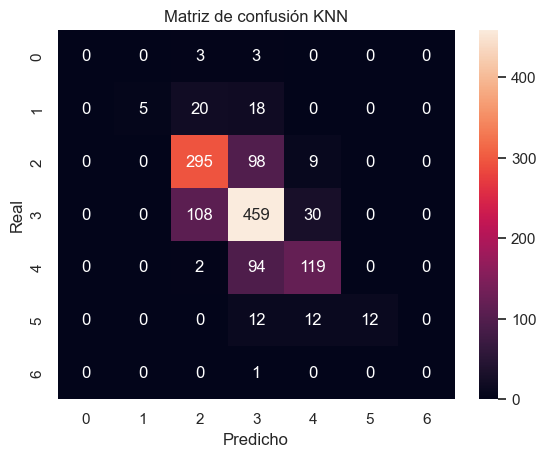

In [1084]:
# Importamos la función para crear la matriz de confusión
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Creamos la matriz comparando valores reales vs predichos
cm = confusion_matrix(y_test, y_pred_knn_clas)

# Dibujamos la matriz como mapa de calor
sns.heatmap(cm, annot=True, fmt="d")

# Títulos del gráfico
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicho")
plt.ylabel("Real")

# Mostrar gráfico
plt.show()

### 3.1.2 NAIVE BAYES
#### GAUSSIAN NB

En este modelo no hemos sacado el mejor hiperparametro ya que no disponemos de gran cantidad de hiperparametros, ademas de no ser de gran importancia los que tiene.

In [1085]:
# Importamos el modelo Naive Bayes para Clasificacion con GaussianNB
from sklearn.naive_bayes import GaussianNB

In [1086]:
# Crear una instancia del modelo.
nb = GaussianNB() # Se inicializa el clasificador

##### **Entrenamiento**

Se entrena utilizando el conjunto de datos de entrenamiento.

Durante el entrenamiento, el algoritmo calcula las distribuciones gaussianas de cada variable para cada clase de calidad del vino. Es decir, estima la media y la varianza de cada característica dentro de cada clase.

In [1087]:
nb.fit(train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


##### **Predicción**

Una vez entrenado el modelo, se utiliza para realizar predicciones sobre el conjunto de datos de prueba.

Estima la calidad del vino para muestras que el modelo no ha visto durante el entrenamiento, lo que permite evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.


In [1088]:
y_pred_nb = nb.predict(test) # Predecimos la calidad del vino

##### **Evaluación**

In [1089]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report Naive Bayes ===")
print(classification_report(y_test, y_pred_nb, labels=nb.classes_, zero_division=0))

=== Classification Report Naive Bayes ===
              precision    recall  f1-score   support

           3       0.06      0.17      0.09         6
           4       0.13      0.16      0.15        43
           5       0.50      0.61      0.55       402
           6       0.56      0.39      0.46       597
           7       0.37      0.56      0.44       215
           8       0.40      0.06      0.10        36
           9       0.00      0.00      0.00         1

    accuracy                           0.47      1300
   macro avg       0.29      0.28      0.26      1300
weighted avg       0.49      0.47      0.46      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales
* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.


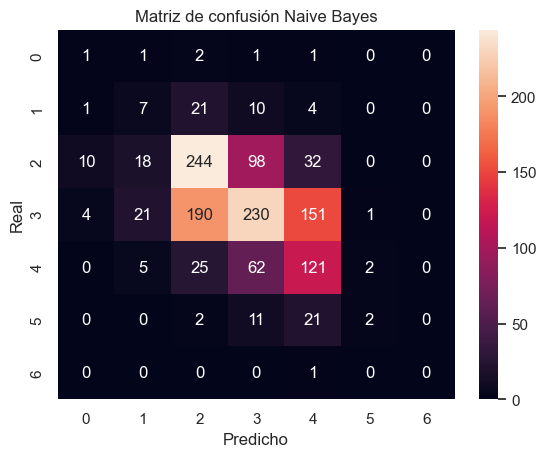

In [1090]:
# Matriz de confusión para Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(cm_nb, annot=True, fmt="d")

plt.title("Matriz de confusión Naive Bayes")
plt.xlabel("Predicho")
plt.ylabel("Real")

plt.show()

### 3.1.3 SVM Clasificación

In [1091]:
# Importamos el modelo SVM para Clasificacion
from sklearn.svm import SVC

Vamos a realizar una búsqueda para encontrar la mejor combinación de hiperparámetros.

Los hiperparámetros que vamos a probar son:

- C: controla el equilibrio entre el error permitido y la complejidad del modelo.

- gamma: controla la influencia de cada muestra en el modelo cuando utilizamos kernels no lineales.


In [1092]:
# Posibles valores de los hiperparámetros
C_values = [0.1, 1, 10, 100, 1000]
gamma_values = [0.001, 0.01, 0.1, 1, 10]

best_score = float("inf") # Guarda el menor error
best_parameters = {} # Guarda los parámetros que producen ese menor error

for C in C_values:
    for gamma in gamma_values:

        svm_clas = SVC(kernel="rbf", C=C, gamma=gamma)

        # Hace cross validation con 4 particiones
        scores = cross_val_score(
            svm_clas, train, y_train,
            cv=4,
            scoring="f1_micro"
        )

        mean_score = -scores.mean() # Convertimos el resultado en MAE positivo

        if mean_score < best_score: # Compara si el error es menor
            best_score = mean_score
            best_parameters = {"C": C, "gamma": gamma}

print("Best parameters:", best_parameters)
print("Best cross-validation score:", best_score)

Best parameters: {'C': 1000, 'gamma': 1}
Best cross-validation score: -0.6220912536270504


Se utiliza el **kernel rbf**, ya que es el que permite modelar relaciones no lineales entre las variables, útil cuando la relación entre las características del dataset y la variable objetivo no sigue un patrón lineal simple, como en nuestro caso.


In [1093]:
# Fijamos la mejor combinacion encontrada
svm_clas_best = SVC(kernel="rbf", C=best_parameters["C"], gamma=best_parameters["gamma"])

##### **Entrenamiento**

Se entrena utilizando el conjunto de datos de entrenamiento.

Durante el entrenamiento, el algoritmo busca un hiperplano que permita separar las diferentes clases de calidad del vino, maximizando el margen de separación entre ellas. En caso de utilizar kernels no lineales, transforma implícitamente el espacio de características para poder encontrar separaciones más complejas.

In [1094]:
svm_clas_best.fit(train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


##### **Predicción**

Ahora hacemos predicciones sobre el conjunto de datos de prueba.

Estima la calidad del vino para muestras que el modelo no ha visto durante el entrenamiento, lo que permite evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.

In [1095]:
y_pred_svm_clas = svm_clas_best.predict(test) # Predecimos la calidad del vino

##### **Evaluación**

In [1096]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report SVM ===")
print(classification_report(y_test, y_pred_svm_clas, labels=svm_clas_best.classes_, zero_division=0))

=== Classification Report SVM ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.36      0.19      0.25        43
           5       0.62      0.63      0.62       402
           6       0.63      0.73      0.68       597
           7       0.71      0.53      0.61       215
           8       0.75      0.33      0.46        36
           9       0.00      0.00      0.00         1

    accuracy                           0.63      1300
   macro avg       0.44      0.34      0.37      1300
weighted avg       0.63      0.63      0.63      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales.

* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.

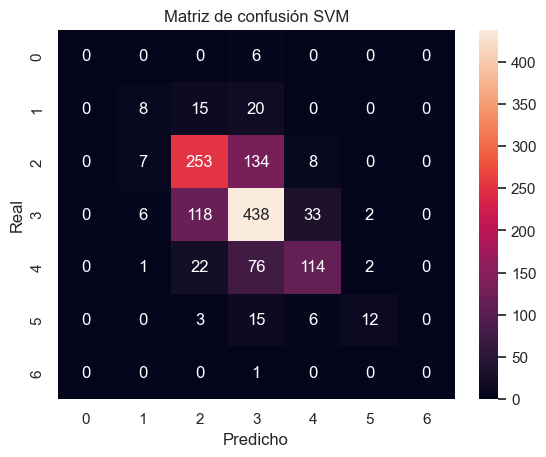

In [1097]:
# Matriz de confusión para Naive Bayes
cm_svm = confusion_matrix(y_test, y_pred_svm_clas)

sns.heatmap(cm_svm, annot=True, fmt="d")

plt.title("Matriz de confusión SVM")
plt.xlabel("Predicho")
plt.ylabel("Real")

plt.show()

### 3.1.4 Arbol de decisión

In [1098]:
# Importamos el modelo de Arbol de decision para clasificación
from sklearn.tree import DecisionTreeClassifier

In [1099]:
# Creamos el modelo de Árbol de Decisión
tree_clas = DecisionTreeClassifier(random_state=42)

#### <u>Sin busqueda de hiperparametros</u>

#### **Entrenamiento**

Se entrena el modelo utilizando el conjunto de datos de entrenamiento y sus correspondientes etiquetas de calidad.

Pd: No es necesario escalar los datos, ya que los árboles de decisión toman decisiones mediante comparaciones entre los valores de las variables.

In [1100]:
# Entrenamos el modelo con los datos de entrenamiento
tree_clas.fit(x_train, y_train)  # No utilizamos los valores escalado

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

##### **Predicción**

Evaluar cómo se comporta el modelo frente a datos que no han sido utilizados durante el entrenamiento, fundamental para analizar su capacidad de generalización.

In [1101]:
# Predecimos la calidad de los vinos en el conjunto de prueba
y_pred_tree = tree_clas.predict(x_test)

##### **Evaluación**

In [1102]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report Árbol de Decisión ===")
print(classification_report(y_test, y_pred_tree, labels=tree_clas.classes_, zero_division=0))

=== Classification Report Árbol de Decisión ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.21      0.21      0.21        43
           5       0.60      0.68      0.64       402
           6       0.66      0.58      0.62       597
           7       0.53      0.58      0.56       215
           8       0.35      0.36      0.36        36
           9       0.00      0.00      0.00         1

    accuracy                           0.59      1300
   macro avg       0.34      0.34      0.34      1300
weighted avg       0.59      0.59      0.59      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales
* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.


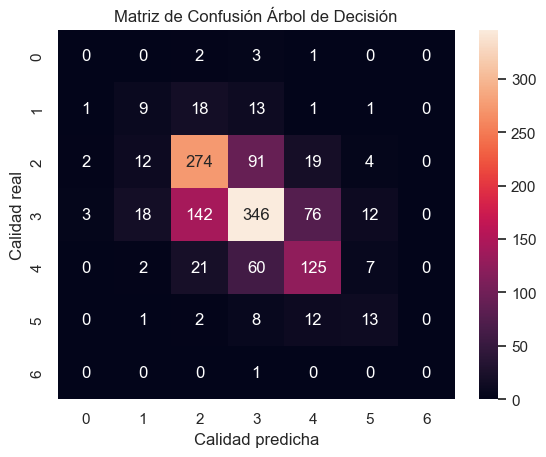

In [1103]:
# Matriz de confusión
cm_tree = confusion_matrix(y_test, y_pred_tree)
sns.heatmap(cm_tree, annot=True, fmt="d")
plt.title("Matriz de Confusión Árbol de Decisión")
plt.xlabel("Calidad predicha")
plt.ylabel("Calidad real")
plt.show()

#### <u>Con busqueda de hiperparametros</u>

El rendimiento de un árbol de decisión depende de diferentes hiperparámetros que controlan su estructura y complejidad.

En este caso vamos a probar:

- max_depth: profundidad máxima que puede alcanzar el árbol.

- min_samples_split: número mínimo de muestras necesarias para dividir un nodo.

- min_samples_leaf: número mínimo de muestras que debe contener cada nodo hoja.

Utilizamos GridSearchCV para probar las diferentes combinaciones de estos valores mediante validación cruzada (cross-validation) con 4 particiones.

F1-micro para seleccionar la mejor configuración, ya que permite evaluar el rendimiento global del clasificador.

In [1104]:
param_grid = {"max_depth": range(1,20), # Numero maximo de niveles en el arbol
              "min_samples_split": range(2,6), #  Numero minimo de muestras necesarias para dividir un nodo
              "min_samples_leaf": range(2,16), # Numero minimo de muestras requeridas en cada nodo hoja
            }

grid_tree = GridSearchCV(
    estimator=tree_clas, 
    param_grid=param_grid,
    cv=4,
    scoring="f1_micro",
    n_jobs=-1
)

##### **Entrenamiento**

En este caso el modelo se entrena utilizando los datos de entrenamiento para aprender las reglas que permiten clasificar la calidad del vino a partir de sus caracteristicas.


In [1105]:
# Entrenamos el modelo con los datos de entrenamiento
grid_tree.fit(x_train, y_train)  # No utilizamos los valores escalado

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(1, 20), 'min_samples_leaf': range(2, 16), 'min_samples_split': range(2, 6)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displaye

Pd: No requieren escalado de los datos, porque toman decisiones basadas en comparaciones entre valores de las variables y no en distancias entre puntos.

##### **Predicción**

Evaluar cómo se comporta el modelo frente a datos que no han sido utilizados durante el entrenamiento, fundamental para analizar su capacidad de generalización.


In [1106]:
# Predecimos la calidad de los vinos en el conjunto de prueba
y_pred_grid_tree = grid_tree.predict(x_test)

##### **Evaluación**

In [1107]:
# Evaluamos el modelo usando métricas de clasificación
print("=== Classification Report Árbol de Decisión ===")
print(classification_report(y_test, y_pred_grid_tree, labels=grid_tree.classes_, zero_division=0))

=== Classification Report Árbol de Decisión ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.13      0.12      0.12        43
           5       0.54      0.60      0.57       402
           6       0.61      0.59      0.60       597
           7       0.50      0.47      0.48       215
           8       0.26      0.19      0.22        36
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1300
   macro avg       0.29      0.28      0.29      1300
weighted avg       0.54      0.54      0.54      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales
* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.


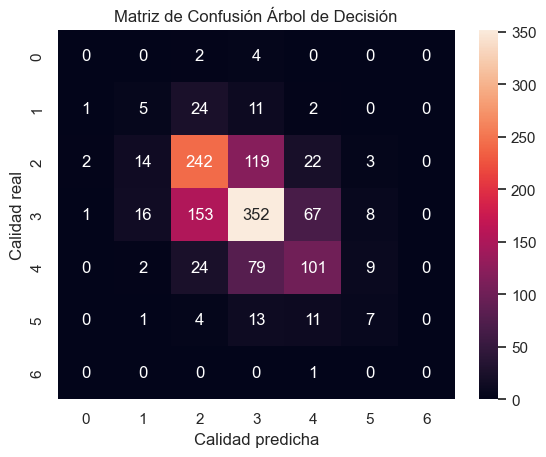

In [1108]:
# Matriz de confusión
cm_tree = confusion_matrix(y_test, y_pred_grid_tree)
sns.heatmap(cm_tree, annot=True, fmt="d")
plt.title("Matriz de Confusión Árbol de Decisión")
plt.xlabel("Calidad predicha")
plt.ylabel("Calidad real")
plt.show()

### 3.1.5 Bosques 
### RANDOM FORESTS Clasificación

In [1109]:
# Importamos el modelo Bosque aleatorio para clasificación
from sklearn.ensemble import RandomForestClassifier

#### <u>Sin busqueda de hiperparametros</u>

In [1110]:
# Creamos el modelo Random Forest para clasificación
rf_clf = RandomForestClassifier(random_state=42)

##### **Entrenamiento**

Cada árbol se entrena con una muestra aleatoria de los datos y utilizando un subconjunto aleatorio de variables, lo que ayuda a  mejora la capacidad de generalización del modelo.

La predicción final se obtiene mediante votación entre los diferentes árboles.


In [1111]:
# Entrenamos el modelo
rf_clf.fit(x_train, y_train) # Como deriba de los arboles tampoco se usa el escalado

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

##### **Predicción**

Este proceso permite evaluar el rendimiento del modelo utilizando datos que no han sido utilizados durante el entrenamiento, lo que ayuda a comprobar su capacidad de generalización.

Las predicciones obtenidas se basan en la votación de los distintos árboles de decisión que componen el modelo Random Forest, asignando como resultado final la clase más votada.


In [1112]:
# Predicción
y_pred_rf = rf_clf.predict(x_test)

##### **Evaluación**

In [1113]:
# Classification report
print("=== Classification Report Random Forest ===")
print(classification_report(y_test, y_pred_rf, labels=rf_clf.classes_, zero_division=0))

=== Classification Report Random Forest ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.71      0.12      0.20        43
           5       0.67      0.71      0.69       402
           6       0.66      0.75      0.70       597
           7       0.71      0.55      0.62       215
           8       0.92      0.33      0.49        36
           9       0.00      0.00      0.00         1

    accuracy                           0.67      1300
   macro avg       0.52      0.35      0.39      1300
weighted avg       0.67      0.67      0.66      1300



##### **Evaluación: Matriz de confusión**

Compara las clases reales con las clases predichas por el modelo, mostrando cuántas predicciones han sido correctas y cuántas incorrectas.

* Las filas de la matriz representan las clases reales
* Las columna representa las clases predichas por el modelo.

Se puede observar en qué clases el modelo funciona mejor y en cuáles comete más errores, proporcionando una visión más completa del comportamiento del clasificador.


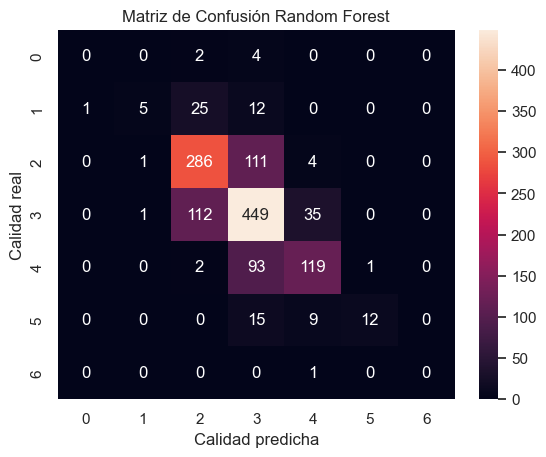

In [1114]:
# Matriz de confusión
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d")
plt.title("Matriz de Confusión Random Forest")
plt.xlabel("Calidad predicha")
plt.ylabel("Calidad real")
plt.show()

#### <u>Con busqueda de hiperparametros</u>

El rendimiento del modelo Random Forest depende de varios hiperparámetros que permiten controlar cómo se construyen los árboles que forman el bosque.

Los principales hiperparámetros que vamos a probar son:

- n_estimators: número de árboles que forman el bosque.

- max_depth: profundidad máxima que puede alcanzar cada árbol.

- min_samples_split: número mínimo de muestras necesarias para dividir un nodo.

- min_samples_leaf: número mínimo de muestras que debe contener un nodo hoja.

- max_features: número de variables que se consideran al buscar la mejor división de cada nodo.

Para encontrar la mejor combinación de estos hiperparámetros utilizamos GridSearchCV, que prueba las distintas combinaciones posibles mediante validación cruzada (cross-validation) con 4 particiones.

Seleccionamos la combinación que obtiene el mejor resultado utilizando la métrica F1-micro, que calcula el F1-score de cada clase y realiza la media, dando la misma importancia a todas las clases.

In [1115]:
# Hiperparámetros que queremos probar
param_grid_forest = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

# Búsqueda de los mejores hiperparámetros
grid_forest = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_forest,
    cv=4,
    scoring="f1_micro",
    n_jobs=-1
)

##### **Entrenamiento**

Una vez definidos los hiperparámetros que queremos probar, se inicia la búsqueda utilizando el conjunto de datos de entrenamiento.

GridSearchCV entrena y evalúa los diferentes modelos mediante validación cruzada, seleccionando automáticamente la combinación de hiperparámetros que obtiene el mejor resultado.

Finalmente, el mejor modelo encontrado queda entrenado con todos los datos de entrenamiento.

In [1116]:
grid_forest.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and p

##### **Predicción**

Una vez encontrada y entrenada la mejor configuración del modelo Random Forest, se utiliza para realizar predicciones sobre el conjunto de datos de prueba.

De esta forma podemos comprobar cómo se comporta el modelo con muestras que no ha utilizado durante el entrenamiento y evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.

In [1117]:
# Predicciones con el mejor modelo
y_pred_forest = grid_forest.predict(x_test)

##### **Evaluación**

In [1118]:
# Informe de clasificación
print("=== Classification Report Random Forest ===")
print(classification_report(y_test, y_pred_forest, labels=grid_forest.classes_, zero_division = 0))


=== Classification Report Random Forest ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.62      0.12      0.20        43
           5       0.68      0.73      0.70       402
           6       0.67      0.76      0.71       597
           7       0.74      0.57      0.64       215
           8       0.86      0.33      0.48        36
           9       0.00      0.00      0.00         1

    accuracy                           0.68      1300
   macro avg       0.51      0.36      0.39      1300
weighted avg       0.68      0.68      0.67      1300



##### **Evalucación: Matriz de confusión**

La matriz de confusión compara las clases reales con las clases predichas por el modelo Random Forest optimizado.
- Las filas representan las clases reales.
- Las columnas representan las clases predichas por el modelo.
Permite observar cuántas predicciones han sido correctas y en qué categorías se producen más errores.

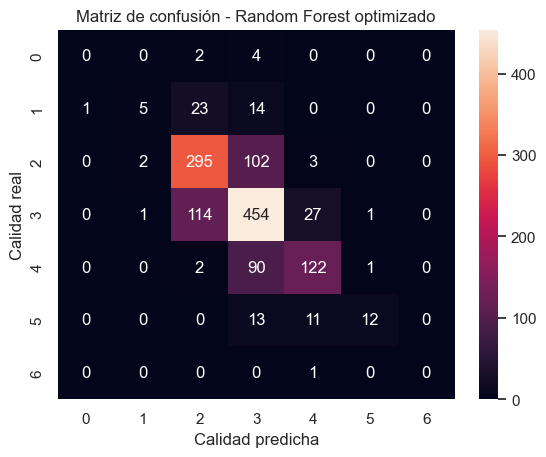

In [1119]:
# Matriz de confusión
cm_rf = confusion_matrix(y_test, y_pred_forest)

sns.heatmap(cm_rf, annot=True, fmt="d")
plt.title("Matriz de confusión - Random Forest optimizado")
plt.xlabel("Calidad predicha")
plt.ylabel("Calidad real")
plt.show()

##### **Evaluación**

## 3.2 Regresión

### 3.2.1 KNN Regresión

In [1120]:
# Importamos el modelo KNN para regresión
from sklearn.neighbors import KNeighborsRegressor

#### <u>Sin busqueda de hiperparametros</u>

In [1121]:
# Creamos el modelo KNN para regresión
knn_reg = KNeighborsRegressor(n_neighbors=5)

##### **Entrenamiento**

Se entrena el modelo utilizando los datos de entrenamiento previamente escalados. El algoritmo almacena las muestras y sus valores de calidad para utilizarlos posteriormente al realizar predicciones.

In [1122]:
# Entrenamos el modelo
knn_reg.fit(train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


##### **Prediccion**

Una vez entrenado el modelo, realizamos predicciones sobre el conjunto de prueba para estimar la calidad de vinos que no ha visto anteriormente.

In [1123]:
# Realizamos las predicciones
y_pred_knn_reg = knn_reg.predict(test)

##### **Evaluación**

Para evaluar el rendimiento del modelo, se utilizan varias métricas que permiten medir el error entre los valores reales y los valores predichos por el modelo:
* MAE.
* MSE.
* R2.


In [1124]:
# Calculamos las métricas
mae_knn = mean_absolute_error(y_test, y_pred_knn_reg)
mse_knn = mean_squared_error(y_test, y_pred_knn_reg)
r2_knn = r2_score(y_test, y_pred_knn_reg)

# Mostramos los resultados
print("KNNReg MAE:", mae_knn)
print("KNNReg MSE:", mse_knn)
print("KNNReg R2:", r2_knn)

KNNReg MAE: 0.53
KNNReg MSE: 0.4925230769230769
KNNReg R2: 0.3331186145188376


#### <u>Con busqueda de hiperparámetros</u>

En esta parte se utiliza el algoritmo K-Nearest Neighbors para regresión (KNN Regressor), cuyo objetivo es predecir un valor numérico continuo, en este caso la calidad del vino.

El rendimiento del modelo depende de varios **hiperparámetros**:

* n_neighbors (K): número de vecinos.
* weights: tipos de pesos.
* metric: métrica distancia.

Buscamos la mejor configuración del modelo probando distintas combinaciones y evaluando cada modelo mediante **validación cruzada (cross-validation)** con 4 particiones y utiliza la métrica **Mean Absolute Error (MAE)** para evaluar el rendimiento del modelo.


In [1125]:
# Posibles parametros
neighbors_range = range(1, 31) # Para probar valores de K entre 1 y 30
weights_options = ['uniform', 'distance']
metric_options = ['euclidean', 'manhattan']

best_score = float('-inf') # Guarda la mejor precision (inicia en menos infinito, para que cualquier resultado pueda ser mejor que el inicial)
best_params = {} # Parametros que producen esa mejor precision

# Bucles para probar combinaciones
for weight in weights_options:
    for metric_option in metric_options:
        for neighbors in neighbors_range:

            knn_reg = KNeighborsRegressor(n_neighbors=neighbors, weights=weight, metric=metric_option) # Crea el modelo con la combinación actual de parámetros.
            # Hace cross validation con 4 particiones, con 3 entrena y con 1 evalua
            scores = cross_val_score(knn_reg, train, y_train, cv=4, scoring='neg_mean_absolute_error') # Maximizar la métrica, pero MAE es un error que queremos minimizar
            mean_score = scores.mean() # Calcula la precision media del modelo de las 4 partes

            if mean_score > best_score: # Compara si la precision media calculada es mejor el guardado como mejor
                best_score = mean_score # Se pone como mejor precision el calculado en este momento
                best_params = {'n_neighbors': neighbors, 'weights': weight, 'metric': metric_option}

print("Best parameters:", best_params)
print("Best cross-validation score (neg MAE):", best_score)

Best parameters: {'n_neighbors': 15, 'weights': 'distance', 'metric': 'manhattan'}
Best cross-validation score (neg MAE): -0.4286715289599501


Se selecciona la combinación que ha obtenido el mejor rendimiento utilizando la búsqueda de hiperparámetros mediante validación cruzada. 

Con estos valores óptimos se construye el modelo final de KNN, que será entrenado utilizando el conjunto de datos de entrenamiento.


In [1126]:
# Parametros
n_neighbors = best_params["n_neighbors"]
weights = best_params["weights"]
metric = best_params["metric"]

# Fija la mejor encontrada
knn_reg = KNeighborsRegressor(n_neighbors= n_neighbors, weights=weights, metric = metric)

# Entrena el modelo con datos de entrenamiento escalados y las etiquetas de calidad del vino
knn_reg.fit(X = train, y = y_train) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'manhattan'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


##### **Predicción**

Una vez entrenado el modelo KNN con los mejores hiperparámetros, se utiliza para realizar predicciones sobre el conjunto de datos de prueba.

Comprueba cómo se comporta el modelo con datos que no ha visto durante el entrenamiento, lo que permite evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.

In [1127]:
y_pred_reg = knn_reg.predict(test)

##### **Evaluación**

Para evaluar el rendimiento del modelo, se utilizan varias métricas que permiten medir el error entre los valores reales y los valores predichos por el modelo:
* MAE.
* MSE.
* R2.


In [1128]:
# Calculamos diferentes métricas para evaluar el modelo

mae_knn_grid = mean_absolute_error(y_test, y_pred_reg)
mse_knn_grid = mean_squared_error(y_test, y_pred_reg)
r2_knn_grid = r2_score(y_test, y_pred_reg)

# Mostramos los resultados
print("KNNReg MAE:", mae_knn_grid)
print("KNNReg MSE:", mse_knn_grid)
print("KNNReg R2:", r2_knn_grid)

KNNReg MAE: 0.40475666674452837
KNNReg MSE: 0.3790396252178869
KNNReg R2: 0.4867763922926931


### 3.2.2 SVM Regresión

In [1129]:
# Importamos el modelo de SVM para regresión
from sklearn.svm import SVR

#### <u>Sin busqueda de hiperparametros</u>

In [1130]:
# Creamos el modelo SVM para regresión
svm_reg = SVR(kernel='rbf')

Se utiliza el **kernel rbf** porque permite modelar relaciones no lineales entre las variables, lo que resulta especialmente útil cuando la relación entre las características del dataset y la variable objetivo no sigue un patrón lineal simple.


##### **Entrenamiento**

Se entrena utilizando el conjunto de datos de entrenamiento.

El modelo aprende la relación entre las variables de entrada  y la variable objetivo. SVM aproxima los datos minimizando el error de predicción, mientras mantiene la mayor generalización posible.

Utilizando el conjunto de entrenamiento, datos que no han sido utilizados durante el aprendizaje.

In [1131]:
# Entrenamos el modelo con los datos de entrenamiento
svm_reg.fit(train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


##### **Predicción**

Una vez entrenado el modelo, se utiliza para realizar predicciones sobre el conjunto de datos de prueba.

Estima la calidad del vino para muestras que el modelo no ha visto durante el entrenamiento, lo que permite evaluar su capacidad de generalización.

Las predicciones obtenidas se almacenan en una nueva variable.


In [1132]:
# Usamos el modelo para predecir la calidad del vino
y_pred_svm = svm_reg.predict(test)

##### **Evaluación**

Para evaluar el rendimiento del modelo, se utilizan varias métricas que permiten medir el error entre los valores reales y los valores predichos por el modelo:
* MAE.
* MSE.
* R2.


In [1133]:
# Calculamos las métricas para evaluar el modelo

mae_svm = mean_absolute_error(y_test, y_pred_svm)
mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm)

print("SVR MAE:", mae_svm)
print("SVR MSE:", mse_svm)
print("SVR R2:", r2_svm)

SVR MAE: 0.5126235598895458
SVR MSE: 0.4599034116444077
SVR R2: 0.3772859816823628


#### <u>Con busqueda de hiperparametros</u>

Vamos a realizar una búsqueda para encontrar la mejor combinación de hiperparámetros.

Los hiperparámetros que vamos a probar son:

- C: controla el equilibrio entre el error permitido y la complejidad del modelo.

- epsilon: define el margen de error dentro del cual no se penalizan las predicciones.

- gamma: controla la influencia de cada muestra en el modelo cuando utilizamos kernels no lineales.

Utilizaremos GridSearchCV con 4 particiones y MAE como métrica de evaluación.

In [1134]:
# Hiperparámetros que queremos probar
param_grid_svm = {
    "C": [0.1, 1, 10, 100, 1000],
    "gamma": [0.001, 0.01, 0.1, 1, 10],
    "epsilon": [0.1, 0.2]

}

# Búsqueda de los mejores hiperparámetros
grid_svm = GridSearchCV(
    estimator=svm_reg,
    param_grid=param_grid_svm,
    cv=4,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

##### **Entrenamiento**

Se inicia la búsqueda de hiperparámetros utilizando los datos de entrenamiento.

GridSearchCV prueba las diferentes combinaciones y utiliza validación cruzada para seleccionar aquella que obtiene el menor error absoluto medio.

In [1135]:
# Entrenamos y buscamos los mejores hiperparámetros
grid_svm.fit(train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVR()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'epsilon': [0.1, 0.2], 'gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

##### **Predicción**

Una vez encontrada la mejor configuración, utilizamos el mejor modelo para realizar predicciones sobre el conjunto de prueba.


In [1136]:
# Realizamos las predicciones
y_pred_svm_grid = grid_svm.predict(test)

##### **Evaluación**

Evaluamos el rendimiento del modelo utilizando las mismas métricas que en el resto de modelos de regresión.

In [1137]:
# Calculamos las métricas
mae_svm_grid = mean_absolute_error(y_test, y_pred_svm_grid)
mse_svm_grid = mean_squared_error(y_test, y_pred_svm_grid)
r2_svm_grid = r2_score(y_test, y_pred_svm_grid)

# Mostramos los resultados
print("SVR optimizado MAE:", mae_svm_grid)
print("SVR optimizado MSE:", mse_svm_grid)
print("SVR optimizado R2:", r2_svm_grid)

SVR optimizado MAE: 0.47168075094181366
SVR optimizado MSE: 0.4621811365648683
SVR optimizado R2: 0.3742019183726979


### 3.2.3 Arbol de decisión

In [1138]:
# Importamos el modelo Arbol para regresión
from sklearn.tree import DecisionTreeRegressor

In [1139]:
# Creamos el modelo de Árbol de Decisión para regresión
tree_reg = DecisionTreeRegressor(random_state=42)

#### <u>Sin busqueda de hiperparametros</u>

##### **Entrenamiento**

Durante el entrenamiento, el modelo analiza las variables del dataset y construye una estructura de árbol que divide los datos en diferentes regiones del espacio de características. Cada división se realiza con el objetivo de reducir el error de predicción dentro de cada grupo de datos.

De esta forma, el árbol aprende a estimar la calidad del vino a partir de sus propiedades.


In [1140]:
# Entrenamos el modelo con los datos de entrenamiento
tree_reg.fit(x_train, y_train)  # Los árboles no requieren escalado de datos

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

### **Predicción**

Estimamos la calidad del vino a partir de datos que no han sido visto durante el proceso de entrenamiento.


In [1141]:
# Predecimos la calidad de los vinos en el conjunto de prueba
y_pred_tree_reg = tree_reg.predict(x_test)

### **Evaluación**

Para evaluar el rendimiento del modelo, se utilizan varias métricas que permiten medir el error entre los valores reales y los valores predichos por el modelo:
* MAE.
* MSE.
* R2.


In [1142]:
# Evaluamos el modelo usando métricas de regresión
mae_tree = mean_absolute_error(y_test, y_pred_tree_reg)
mse_tree = mean_squared_error(y_test, y_pred_tree_reg)
r2_tree = r2_score(y_test, y_pred_tree_reg)

print("TreeReg MAE:", mae_tree)
print("TreeReg MSE:", mse_tree)
print("TreeReg R2:", r2_tree)

TreeReg MAE: 0.5084615384615384
TreeReg MSE: 0.7284615384615385
TreeReg R2: 0.013655475650245497


#### <u>Con busqueda de hiperparametros</u>

In [1143]:
# Hiperparámetros que queremos probar
param_grid_tree_reg = {
    "max_depth": range(2, 21),
    "min_samples_split": range(2, 6),
    "min_samples_leaf": range(1, 6),
    "max_features": [None, "sqrt"]
}

# Búsqueda de los mejores hiperparámetros
grid_tree_reg = GridSearchCV(
    estimator=tree_reg,
    param_grid=param_grid_tree_reg,
    cv=4,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

##### **Entrenamiento**

Entrenamos el modelo utilizando los datos de entrenamiento.

GridSearchCV prueba las diferentes combinaciones de hiperparámetros y selecciona aquella que obtiene el menor MAE medio durante la validación cruzada.

In [1144]:
# Entrenamos y buscamos los mejores hiperparámetros
grid_tree_reg.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(2, 21), 'max_features': [None, 'sqrt'], 'min_samples_leaf': range(1, 6), 'min_samples_split': range(2, 6)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for

##### **Prediccion**

Utilizamos el mejor árbol encontrado para realizar predicciones sobre el conjunto de prueba.

In [1145]:
# Realizamos las predicciones
y_pred_tree_grid = grid_tree_reg.predict(x_test)

##### **Evaluación**

Evaluamos el rendimiento del árbol optimizado utilizando MAE, MSE y R2.

In [1146]:
# Calculamos las métricas
mae_tree_grid = mean_absolute_error(y_test, y_pred_tree_grid)
mse_tree_grid = mean_squared_error(y_test, y_pred_tree_grid)
r2_tree_grid = r2_score(y_test, y_pred_tree_grid)

# Mostramos los resultados
print("TreeReg optimizado MAE:", mae_tree_grid)
print("TreeReg optimizado MSE:", mse_tree_grid)
print("TreeReg optimizado R2:", r2_tree_grid)

TreeReg optimizado MAE: 0.5091107902108983
TreeReg optimizado MSE: 0.719118023670285
TreeReg optimizado R2: 0.02630669217431514


Pd: No es necesario escalar los datos para los árboles de decisión, ya que utilizan comparaciones entre los valores de las variables para realizar las divisiones.

### 3.2.4 Bosques
### RANDOM FORESTS Regresión

In [1147]:
# Importamos el modelo Bosque aleatorio para regresión
from sklearn.ensemble import RandomForestRegressor

In [1148]:
# Creamos el modelo Random Forest para regresión
rf_reg = RandomForestRegressor(random_state=42)

#### <u>Sin busqueda de hiperparametros</u>

##### **Entrenamiento**

Durante el entrenamiento, el algoritmo construye varios árboles de decisión utilizando:
* Muestras aleatorias del conjunto de datos 
* Subconjuntos de variables. 
Cada árbol genera una predicción y el resultado final del modelo se obtiene como la media de las predicciones de todos los árboles.


In [1149]:
# Entrenamos el modelo
rf_reg.fit(x_train, y_train) # Como deriba de los arboles tampoco se usa el escalado

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

##### **Predicción**

Las predicciones obtenidas corresponden a los valores estimados por el árbol en función de las reglas aprendidas durante el entrenamiento y se almacenan en una nueva variable para posteriormente evaluar el rendimiento del modelo mediante diferentes métricas de regresión.


In [1150]:
# Predicción
y_pred_rf_reg = rf_reg.predict(x_test)

##### **Evaluación**

Para evaluar el rendimiento del modelo, se utilizan varias métricas que permiten medir el error entre los valores reales y los valores predichos por el modelo:
* MAE.
* MSE.
* R2.


In [1151]:
# Evaluación
mae_rf = mean_absolute_error(y_test, y_pred_rf_reg)
mse_rf = mean_squared_error(y_test, y_pred_rf_reg)
r2_rf = r2_score(y_test, y_pred_rf_reg)

print("RFReg MAE:", mae_rf)
print("RFReg MSE:", mse_rf)
print("RFReg R2:", r2_rf)

RFReg MAE: 0.4378538461538462
RFReg MSE: 0.3713522307692308
RFReg R2: 0.49718520459177784


#### <u>Con busqueda de hiperparametros</u>

Vamos a realizar una búsqueda de los mejores hiperparámetros para mejorar su capacidad de predicción.

Los hiperparámetros que vamos a probar son:

- n_estimators: número de árboles que forman el bosque.

- max_depth: profundidad máxima de cada árbol.

- min_samples_split: número mínimo de muestras necesarias para dividir un nodo.

- min_samples_leaf: número mínimo de muestras que debe contener cada nodo hoja.

- max_features: número de variables consideradas para realizar cada división.

Utilizaremos GridSearchCV con 4 particiones y MAE como métrica de evaluación.

In [1152]:
# Hiperparámetros que queremos probar
param_grid_rf_reg = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

# Búsqueda de los mejores hiperparámetros
grid_rf_reg = GridSearchCV(
    estimator=rf_reg,
    param_grid=param_grid_rf_reg,
    cv=4,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

##### **Entrenamiento**

Iniciamos la búsqueda utilizando los datos de entrenamiento.

GridSearchCV entrena y evalúa las diferentes combinaciones mediante validación cruzada, seleccionando la configuración que obtiene el menor error absoluto medio.

In [1153]:
# Entrenamos y buscamos los mejores hiperparámetros
grid_rf_reg.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for

##### **Predicción**

Una vez encontrada la mejor configuración, utilizamos el modelo optimizado para realizar predicciones sobre el conjunto de prueba.

In [1154]:
# Realizamos las predicciones
y_pred_rf_grid = grid_rf_reg.predict(x_test)

##### **Evaluación**

Calculamos las métricas para evaluar el rendimiento del Random Forest optimizado.

In [1155]:
# Calculamos las métricas
mae_rf_grid = mean_absolute_error(y_test, y_pred_rf_grid)
mse_rf_grid = mean_squared_error(y_test, y_pred_rf_grid)
r2_rf_grid = r2_score(y_test, y_pred_rf_grid)

# Mostramos los resultados
print("RFReg optimizado MAE:", mae_rf_grid)
print("RFReg optimizado MSE:", mse_rf_grid)
print("RFReg optimizado R2:", r2_rf_grid)

RFReg optimizado MAE: 0.4331038625352938
RFReg optimizado MSE: 0.35907787812046665
RFReg optimizado R2: 0.5138048061573115


## **Comparación de resultados**

Ahora vamos a compara los resultados obtenidos por los modelos de clasificacion, para ello vamos a utilizar de la columna de **f1-score** la fila de **accuracy** obtenida de cada modelo.

Obtuvimos los siguientes resultados:
* **KNN:** 0.55
* **KNN Hiperparametrizado:** 0.68
* **Naive Bayes:** 0.47
* **SVC:** 0.56
* **SVC Hiperparametrizado:** 0.63
* **Arbol de decisión:** 0.59
* **Arbol de decisión Hiperparametrizado:** 0.54
* **Bosque:** 0.67
* **Bosque Hiperparametrizado:** 0.68

Aqui tenemos que elegir el valor de accuracy que mas se aproxime a 1, en este caso las soluciones que dan **el mejor modelo de clasificación** para la prediccion de la calidad del vino son el de **KNN Hiperparametrizado** y el de **Bosque Hiperparametrizado** pero como la hiperpamaterizacion del bosque tarda mas en ejecutarse es mejor opción **KNN Hiperparametrizado**.

Ahora vamos a comprara los resultados obtenidos por los modelos de regresión, para ello vamos a utilizar de la MAE, MSE, R2 de cada modelo.

Vamos a ver los datos obtenidos por cada modelo:

In [1156]:
resultados_reg = pd.DataFrame({
    "Modelo": [
        "KNN",
        "KNN optimizado",
        "SVM",
        "SVM optimizado",
        "Árbol",
        "Árbol optimizado",
        "Random Forest",
        "Random Forest optimizado"
    ],
    "MAE": [
        mae_knn,
        mae_knn_grid,
        mae_svm,
        mae_svm_grid,
        mae_tree,
        mae_tree_grid,
        mae_rf,
        mae_rf_grid
    ],
    "MSE": [
        mse_knn,
        mse_knn_grid,
        mse_svm,
        mse_svm_grid,
        mse_tree,
        mse_tree_grid,
        mse_rf,
        mse_rf_grid
    ],
    "R2": [
        r2_knn,
        r2_knn_grid,
        r2_svm,
        r2_svm_grid,
        r2_tree,
        r2_tree_grid,
        r2_rf,
        r2_rf_grid
    ]
})

resultados_reg

,Modelo,MAE,MSE,R2
0,KNN,0.530000,0.492523,0.333119
1,KNN optimizado,0.404757,0.379040,0.486776
2,SVM,0.512624,0.459903,0.377286
3,SVM optimizado,0.471681,0.462181,0.374202
4,Árbol,0.508462,0.728462,0.013655
5,Árbol optimizado,0.509111,0.719118,0.026307
6,Random Forest,0.437854,0.371352,0.497185
7,Random Forest optimizado,0.433104,0.359078,0.513805


Vamos a quedarnos con el resultado que de menor error y mayor R2, comparando todos los modelos observamos que **los mejores modelos para regresión** es **Random Forests optimizado**, ya que es el que cumple con las condiciones dichas.

Ahora, para elegir si coger el mejor modelo de clasificación o el mejor modelo de regresión, debemos ver que nos piden, en este caso es agrupar por puntuaciones exactas, 1, 2, 3... Por lo que se trataría de un problema de clasificacion y habría que utilizar el **KNN Hiperparametrizado** 